In [1]:
#import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
#Read the CSV file
df=pd.read_csv('cricket-data.csv',na_values=['-'])

In [3]:
df.head()

,Player,Span,Mat,Inns,NO,Runs,HS,Ave,BF,SR,100,50,0,4s,6s
0,DG Bradman (AUS),1928-1948,52,80,10,6996,334,99.94,9800+,58.60,29,13,7.0,626+,6
1,PHKD Mendis (SL),2022-2025,12,21,2,1184,182*,62.31,1839,64.38,5,4,NaN,123,23
2,AC Voges (AUS),2015-2016,20,31,7,1485,269*,61.87,2667,55.68,5,4,2.0,186,5
3,RG Pollock (SA),1963-1970,23,41,4,2256,274,60.97,1707+,54.48,7,11,1.0,246+,11
4,GA Headley (WI),1930-1954,22,40,4,2190,270*,60.83,416+,56.00,10,5,2.0,104+,1


In [4]:
#Rename columns
df=df.rename(columns={'Mat':'Matches','NO':'Not_Out','HS':'Highest_Strike','Ave':'Average','BF':'Ball_Faced','SR':'Strike_Rate'})

In [5]:
#Check null values
df.isnull().any()

Player            False
Span              False
Matches           False
Inns              False
Not_Out           False
Runs              False
Highest_Strike    False
Average           False
Ball_Faced         True
Strike_Rate        True
100               False
50                False
0                  True
4s                False
6s                False
dtype: bool

In [6]:
#Check how many null values are there
df.isnull().sum()[df.isnull().sum()>0]

Ball_Faced     3
Strike_Rate    3
0              1
dtype: int64

In [7]:
#Replace NA values with Zero(0)
df['Ball_Faced']=df['Ball_Faced'].fillna(0)
df['Strike_Rate']=df['Strike_Rate'].fillna(0)
df['0']=df['0'].fillna(0)

In [8]:
df

,Player,Span,Matches,Inns,Not_Out,Runs,Highest_Strike,Average,Ball_Faced,Strike_Rate,100,50,0,4s,6s
0,DG Bradman (AUS),1928-1948,52,80,10,6996,334,99.94,9800+,58.60,29,13,7.0,626+,6
1,PHKD Mendis (SL),2022-2025,12,21,2,1184,182*,62.31,1839,64.38,5,4,0.0,123,23
2,AC Voges (AUS),2015-2016,20,31,7,1485,269*,61.87,2667,55.68,5,4,2.0,186,5
3,RG Pollock (SA),1963-1970,23,41,4,2256,274,60.97,1707+,54.48,7,11,1.0,246+,11
4,GA Headley (WI),1930-1954,22,40,4,2190,270*,60.83,416+,56.00,10,5,2.0,104+,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
57,KD Walters (AUS),1965-1981,74,125,14,5357,250,48.26,8662+,49.16,15,33,4.0,525+,23
58,GC Smith (ICC/SA),2002-2014,117,205,13,9265,277,48.25,15525,59.67,27,38,11.0,1165,24
59,WH Ponsford (AUS),1924-1934,29,48,4,2122,266,48.22,3118+,44.77,7,6,1.0,119+,0
60,SJ McCabe (AUS),1930-1938,39,62,5,2748,232,48.21,3217+,60.02,6,13,4.0,241+,5+


In [9]:
#check duplicate values
print(df.duplicated().sum())

0


In [10]:
# Split the 'Span' column into two columns (Start and End Date).
df[['Start_Date','End_Date']]=df['Span'].str.split('-',expand=True)

In [11]:
df.head()

,Player,Span,Matches,Inns,Not_Out,Runs,Highest_Strike,Average,Ball_Faced,Strike_Rate,100,50,0,4s,6s,Start_Date,End_Date
0,DG Bradman (AUS),1928-1948,52,80,10,6996,334,99.94,9800+,58.60,29,13,7.0,626+,6,1928,1948
1,PHKD Mendis (SL),2022-2025,12,21,2,1184,182*,62.31,1839,64.38,5,4,0.0,123,23,2022,2025
2,AC Voges (AUS),2015-2016,20,31,7,1485,269*,61.87,2667,55.68,5,4,2.0,186,5,2015,2016
3,RG Pollock (SA),1963-1970,23,41,4,2256,274,60.97,1707+,54.48,7,11,1.0,246+,11,1963,1970
4,GA Headley (WI),1930-1954,22,40,4,2190,270*,60.83,416+,56.00,10,5,2.0,104+,1,1930,1954


In [12]:
#Remove Span column
df.drop('Span',inplace=True,axis=1)

In [13]:
df

,Player,Matches,Inns,Not_Out,Runs,Highest_Strike,Average,Ball_Faced,Strike_Rate,100,50,0,4s,6s,Start_Date,End_Date
0,DG Bradman (AUS),52,80,10,6996,334,99.94,9800+,58.60,29,13,7.0,626+,6,1928,1948
1,PHKD Mendis (SL),12,21,2,1184,182*,62.31,1839,64.38,5,4,0.0,123,23,2022,2025
2,AC Voges (AUS),20,31,7,1485,269*,61.87,2667,55.68,5,4,2.0,186,5,2015,2016
3,RG Pollock (SA),23,41,4,2256,274,60.97,1707+,54.48,7,11,1.0,246+,11,1963,1970
4,GA Headley (WI),22,40,4,2190,270*,60.83,416+,56.00,10,5,2.0,104+,1,1930,1954
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
57,KD Walters (AUS),74,125,14,5357,250,48.26,8662+,49.16,15,33,4.0,525+,23,1965,1981
58,GC Smith (ICC/SA),117,205,13,9265,277,48.25,15525,59.67,27,38,11.0,1165,24,2002,2014
59,WH Ponsford (AUS),29,48,4,2122,266,48.22,3118+,44.77,7,6,1.0,119+,0,1924,1934
60,SJ McCabe (AUS),39,62,5,2748,232,48.21,3217+,60.02,6,13,4.0,241+,5+,1930,1938


In [14]:
#Change Datatype for Start & End Date

In [15]:
df.dtypes

Player             object
Matches             int64
Inns                int64
Not_Out             int64
Runs                int64
Highest_Strike     object
Average           float64
Ball_Faced         object
Strike_Rate       float64
100                 int64
50                  int64
0                 float64
4s                 object
6s                 object
Start_Date         object
End_Date           object
dtype: object

In [16]:
df['Start_Date']=df['Start_Date'].astype('int')
df['End_Date']=df['End_Date'].astype('int')

In [17]:
#Player column
df[['Player','Country']]=df['Player'].str.split('(',expand=True)

In [18]:
df.head()

,Player,Matches,Inns,Not_Out,Runs,Highest_Strike,Average,Ball_Faced,Strike_Rate,100,50,0,4s,6s,Start_Date,End_Date,Country
0,DG Bradman,52,80,10,6996,334,99.94,9800+,58.60,29,13,7.0,626+,6,1928,1948,AUS)
1,PHKD Mendis,12,21,2,1184,182*,62.31,1839,64.38,5,4,0.0,123,23,2022,2025,SL)
2,AC Voges,20,31,7,1485,269*,61.87,2667,55.68,5,4,2.0,186,5,2015,2016,AUS)
3,RG Pollock,23,41,4,2256,274,60.97,1707+,54.48,7,11,1.0,246+,11,1963,1970,SA)
4,GA Headley,22,40,4,2190,270*,60.83,416+,56.00,10,5,2.0,104+,1,1930,1954,WI)


In [19]:
df['Country']=df['Country'].str.replace(')',"")

In [20]:
df.head()

,Player,Matches,Inns,Not_Out,Runs,Highest_Strike,Average,Ball_Faced,Strike_Rate,100,50,0,4s,6s,Start_Date,End_Date,Country
0,DG Bradman,52,80,10,6996,334,99.94,9800+,58.60,29,13,7.0,626+,6,1928,1948,AUS
1,PHKD Mendis,12,21,2,1184,182*,62.31,1839,64.38,5,4,0.0,123,23,2022,2025,SL
2,AC Voges,20,31,7,1485,269*,61.87,2667,55.68,5,4,2.0,186,5,2015,2016,AUS
3,RG Pollock,23,41,4,2256,274,60.97,1707+,54.48,7,11,1.0,246+,11,1963,1970,SA
4,GA Headley,22,40,4,2190,270*,60.83,416+,56.00,10,5,2.0,104+,1,1930,1954,WI


In [21]:
df['Highest_Strike'].unique()

array(['334', '182*', '269*', '274', '270*', '194', '243', '256', '207',
       '317', '336*', '365*', '319', '211', '239', '220', '364', '224',
       '122', '251', '183', '227', '247*', '231', '248*', '400*', '214*',
       '280*', '270', '223', '313', '257', '201*', '232*', '195', '203*',
       '236*', '200', '262', '380', '278*', '205', '208*', '291', '278',
       '374', '329', '261', '215*', '329*', '144*', '189*', '250', '277',
       '266', '232', '127'], dtype=object)

In [22]:
df['4s'].unique()

array(['626+', '123', '186', '246+', '104+', '202+', '125+', '591+',
       '258+', '246', '419+', '593+', '1491', '276+', '1116', '107+',
       '358+', '1488', '37+', '1031', '65+', '124', '755', '115+',
       '2058+', '1559', '207', '788+', '1654', '957', '1082', '1509',
       '102+', '543', '685', '1285', '908+', '1175', '1394', '1049',
       '1024', '1161', '165', '952+', '342+', '1387', '1105', '240+',
       '38+', '1233', '148', '978', '123+', '41+', '51+', '633', '427+',
       '525+', '1165', '119+', '241+', '53+'], dtype=object)

In [23]:
df['6s'].unique()

array(['6', '23', '5', '11', '1', '4', '27', '2', '37', '32+', '51', '8',
       '61', '7', '97', '16', '69', '88', '39', '48', '21', '70', '73',
       '3', '20', '36', '26', '45', '82', '64', '28', '84', '0', '91',
       '24', '5+'], dtype=object)

In [24]:
df['Highest_Strike']=df['Highest_Strike'].str.replace('*',"")
df['Ball_Faced']=df['Ball_Faced'].str.replace('+',"")

df['6s']=df['6s'].str.replace('+',"")
df['4s']=df['4s'].str.replace('+',"")

In [25]:
#change Datatypes
df['Highest_Strike']=df['Highest_Strike'].astype(int)
df['Ball_Faced']=df['Ball_Faced'].astype(float)
df['6s']=df['6s'].astype(int)
df['4s']=df['4s'].astype(int)

In [26]:
df.dtypes

Player             object
Matches             int64
Inns                int64
Not_Out             int64
Runs                int64
Highest_Strike      int64
Average           float64
Ball_Faced        float64
Strike_Rate       float64
100                 int64
50                  int64
0                 float64
4s                  int64
6s                  int64
Start_Date          int64
End_Date            int64
Country            object
dtype: object

In [27]:
#Add Column Career_Length
df['Career_Length']=df['End_Date']-df['Start_Date']

In [28]:
df.head()

,Player,Matches,Inns,Not_Out,Runs,Highest_Strike,Average,Ball_Faced,Strike_Rate,100,50,0,4s,6s,Start_Date,End_Date,Country,Career_Length
0,DG Bradman,52,80,10,6996,334,99.94,9800.0,58.60,29,13,7.0,626,6,1928,1948,AUS,20
1,PHKD Mendis,12,21,2,1184,182,62.31,1839.0,64.38,5,4,0.0,123,23,2022,2025,SL,3
2,AC Voges,20,31,7,1485,269,61.87,2667.0,55.68,5,4,2.0,186,5,2015,2016,AUS,1
3,RG Pollock,23,41,4,2256,274,60.97,1707.0,54.48,7,11,1.0,246,11,1963,1970,SA,7
4,GA Headley,22,40,4,2190,270,60.83,416.0,56.00,10,5,2.0,104,1,1930,1954,WI,24


In [29]:
df['Career_Length'].unique()

array([20,  3,  1,  7, 24, 11,  8, 13, 10,  2, 15, 22, 12, 18, 14,  5, 16,
       17,  9, 21, 19,  6])

In [30]:
#Calculations on DS 13 June
### 1. Find the average career length of Cricketers. 
avg_clen=df['Career_Length'].mean()
print(f"Average career length of Cricketers: \033[1m{avg_clen:,.2f} Years.\033[1m")

Average career length of Cricketers: 12.97 Years.


In [31]:
#Find the Average Batting Strike Rate for cricketers who played over 10 years.
avg_sr=df[df['Career_Length']>10]['Strike_Rate'].mean()
print(f"Average Batting Strike Rate for cricketers who played over 10 years: \033[1m{avg_sr:,.2f}\033[1m")

Average Batting Strike Rate for cricketers who played over 10 years: 47.80


In [32]:
#Find the number of cricketers who played before 1960.
cnt=df[df['Start_Date']<1960]['Player'].count()
print(f"Count of cricketers played before 1960: \033[1m{cnt:,.2f}\033[1m")

Count of cricketers played before 1960: 23.00


In [33]:
#Find max Highest Inns Score by Country.
max_inns=df.groupby('Country')['Highest_Strike'].max().to_frame().sort_values('Highest_Strike', ascending = False)
print(max_inns)

         Highest_Strike
Country                
ICC/WI              400
AUS                 380
SL                  374
WI                  365
ENG                 364
ICC/PAK             329
ICC/IND             319
PAK                 313
SA                  278
ICC/SA              277
NZ                  251
IND                 248
ZIM                 232


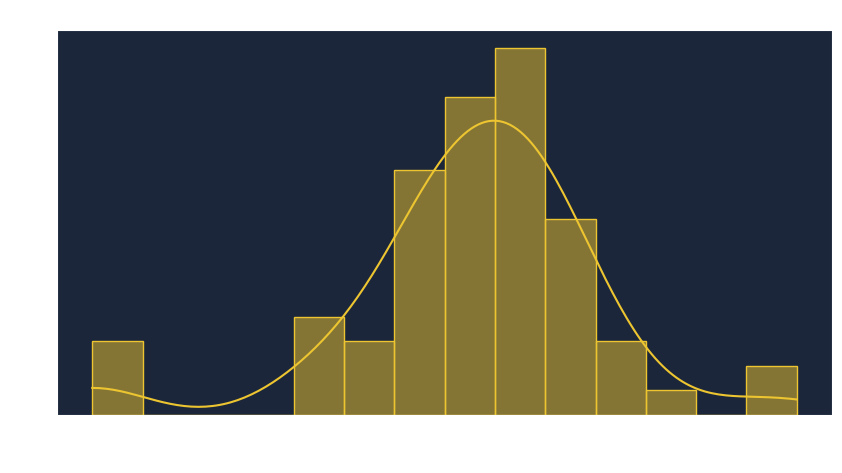

In [34]:
#Visualization on DS
#Distribution of Batting Strike Rate
plt.figure(figsize=(10,5),dpi=100)
plt.rcParams.update({
'figure.facecolor':'#1b263b',
'axes.facecolor':'#1b263b',
'text.color':'white',
'xtick.color':'white',
'ytick.color':'white',
'axes.edgecolor':'white',
'axes.labelcolor':'white',
'axes.titleweight':'bold',
'axes.labelweight':'bold'
})

sns.histplot(data=df,x='Strike_Rate',kde=True,edgecolor='#edc531',color='#edc531')
plt.title('Distribution of Batting Strike Rate')
plt.xlabel("Strike Rate",fontsize=14,weight='bold')
plt.show()

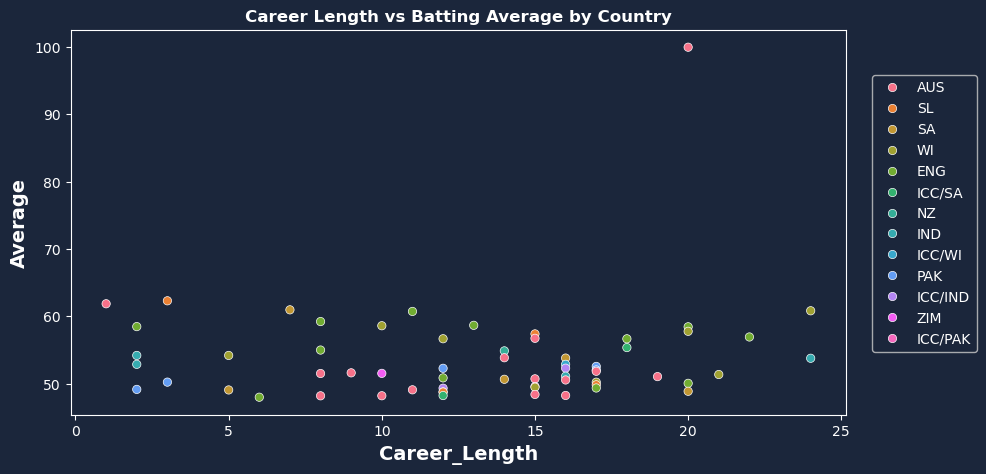

In [35]:

#Career Length vs Batting Average by Country
plt.figure(figsize=(10,5),dpi=100)
plt.rcParams.update({
'figure.facecolor':'#1b263b',
'axes.facecolor':'#1b263b',
'text.color':'white',
'xtick.color':'white',
'ytick.color':'white',
'axes.edgecolor':'white',
'axes.labelcolor':'white',
'axes.titleweight':'bold',
'axes.labelweight':'bold'
})

sns.scatterplot(data=df,x='Career_Length',y='Average',hue='Country')
plt.title('Career Length vs Batting Average by Country')
plt.xlabel("Career_Length",fontsize=14,weight='bold')
plt.ylabel("Average",fontsize=14,weight='bold')
plt.legend(bbox_to_anchor=(1.025, 0.9),loc='upper left')
plt.show()

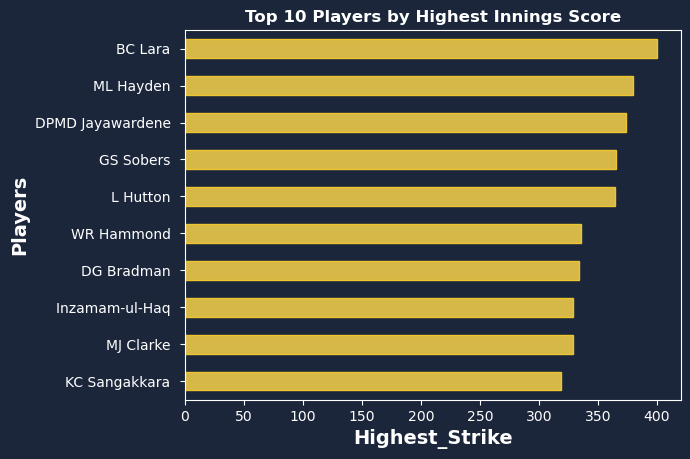

In [36]:
#Top 10 Players by Highest Innings Score
top_10=df.groupby('Player')['Highest_Strike'].max().to_frame().sort_values('Highest_Strike', ascending = False).head(10)
# print(top_10)
plt.rcParams.update({
'figure.facecolor':'#1b263b',
'axes.facecolor':'#1b263b',
'text.color':'white',
'xtick.color':'white',
'ytick.color':'white',
'axes.edgecolor':'white',
'axes.labelcolor':'white',
'axes.titleweight':'bold',
'axes.labelweight':'bold'
})

sns.barplot(data=top_10,x='Highest_Strike',y='Player',width=0.5,edgecolor='#edc531',color='#edc531')
plt.title('Top 10 Players by Highest Innings Score')
plt.xlabel("Highest_Strike",fontsize=14,weight='bold')
plt.ylabel("Players",fontsize=14,weight='bold')
plt.show()

In [38]:
# #Assignment
# 1.Batting Strike Rate Distribution
# 2. Number of Hundreds, Fifties, and Ducks by Country
# 3. Batting Strike Rate vs Career Length
# 4. Batting Strike Rate vs Highest Innings Score
# 5. Cricketers with the Most Hundreds, Fifties, and Ducks
# 6. Top Cricketers by Career Length
# 7. Cricketers by Start Date (Career Start Year)

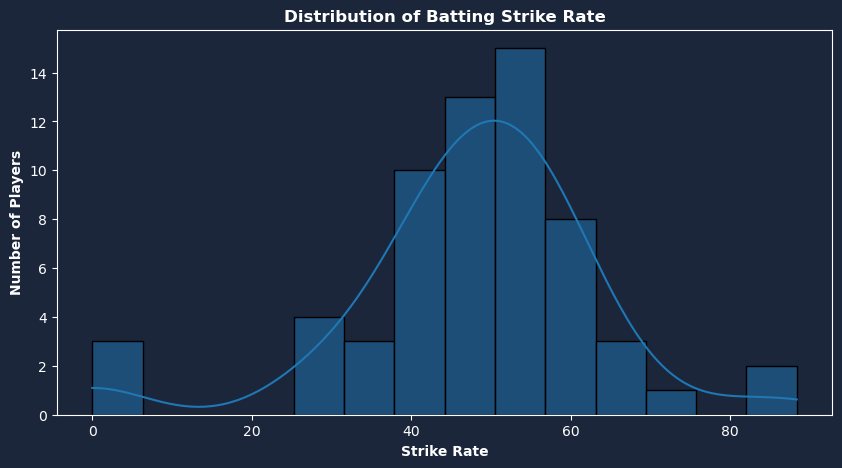

In [39]:
#1.Batting Strike Rate Distribution
# 1. Distribution of Batting Strike Rate

plt.figure(figsize=(10,5))
sns.histplot(data=df, x='Strike_Rate', kde=True)
plt.title('Distribution of Batting Strike Rate')
plt.xlabel('Strike Rate')
plt.ylabel('Number of Players')
plt.show()

In [40]:
#2. Number of Hundreds, Fifties, and Ducks by Country

df.groupby('Country')[['100','50','0']].sum()

,100,50,0
Country,,,
AUS,323,434,134.0
ENG,170,278,58.0
ICC/IND,59,95,24.0
ICC/PAK,25,46,15.0
ICC/SA,72,96,27.0
ICC/WI,34,48,17.0
IND,93,126,32.0
NZ,33,37,11.0
PAK,89,121,40.0


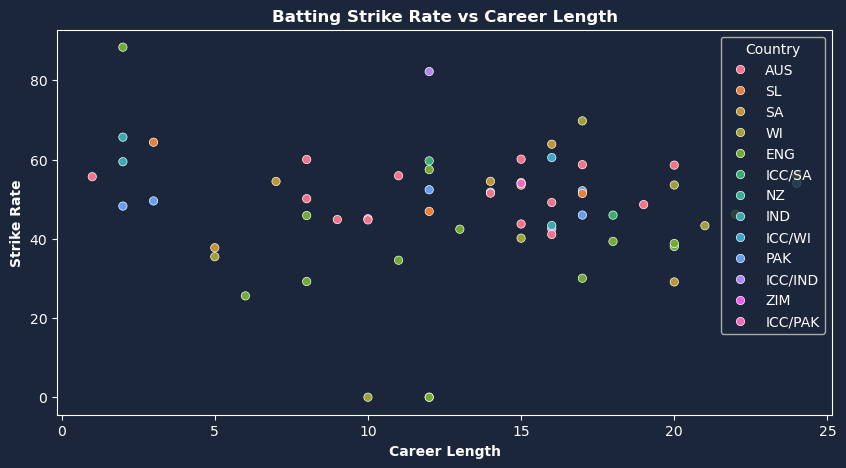

In [41]:
#3. Batting Strike Rate vs Career Length

plt.figure(figsize=(10,5))
sns.scatterplot(data=df, x='Career_Length', y='Strike_Rate', hue='Country')
plt.title('Batting Strike Rate vs Career Length')
plt.xlabel('Career Length')
plt.ylabel('Strike Rate')
plt.show()

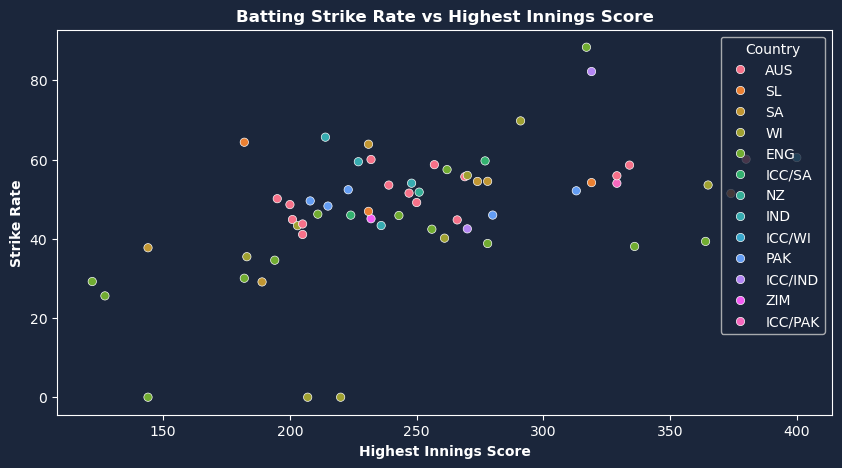

In [42]:
#4. Batting Strike Rate vs Highest Innings Score

plt.figure(figsize=(10,5))
sns.scatterplot(data=df, x='Highest_Strike', y='Strike_Rate', hue='Country')
plt.title('Batting Strike Rate vs Highest Innings Score')
plt.xlabel('Highest Innings Score')
plt.ylabel('Strike Rate')
plt.show()

In [43]:
# 5. Cricketers with Most Hundreds, Fifties and Ducks

print("Top 10 Hundreds:")
print(df[['Player','100']].sort_values('100', ascending=False).head(10))

print("\nTop 10 Fifties:")
print(df[['Player','50']].sort_values('50', ascending=False).head(10))

print("\nTop 10 Ducks:")
print(df[['Player','0']].sort_values('0', ascending=False).head(10))

Top 10 Hundreds:
               Player  100
24      SR Tendulkar    51
17         JH Kallis    45
31        RT Ponting    41
12     KC Sangakkara    38
38           JE Root    36
28          R Dravid    36
14         SPD Smith    36
45  DPMD Jayawardene    34
36       SM Gavaskar    34
30       Younis Khan    34

Top 10 Fifties:
               Player  50
24      SR Tendulkar   68
35     S Chanderpaul   66
38           JE Root   65
41         AR Border   63
28          R Dravid   63
31        RT Ponting   62
17         JH Kallis   58
12     KC Sangakkara   52
37          SR Waugh   50
45  DPMD Jayawardene   50

Top 10 Ducks:
               Player     0
37          SR Waugh   22.0
30       Younis Khan   19.0
31        RT Ponting   17.0
25           BC Lara   17.0
17         JH Kallis   16.0
49          V Sehwag   16.0
45  DPMD Jayawardene   15.0
46    Inzamam-ul-Haq   15.0
35     S Chanderpaul   15.0
24      SR Tendulkar   14.0


            Player Country  Career_Length
24   SR Tendulkar      IND             24
4      GA Headley       WI             24
13       JB Hobbs      ENG             22
35  S Chanderpaul       WI             21
0      DG Bradman      AUS             20
53     B Mitchell       SA             20
44    DCS Compton      ENG             20
11      GS Sobers       WI             20
10     WR Hammond      ENG             20
37       SR Waugh      AUS             19


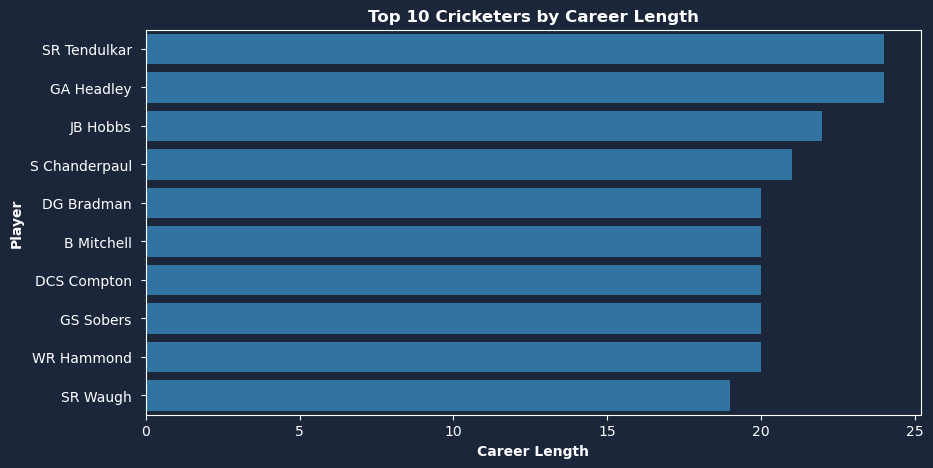

In [44]:
# 6. Top Cricketers by Career Length

top_career = df[['Player','Country','Career_Length']].sort_values(
    'Career_Length', ascending=False
).head(10)

print(top_career)

plt.figure(figsize=(10,5))
sns.barplot(data=top_career, x='Career_Length', y='Player')
plt.title('Top 10 Cricketers by Career Length')
plt.xlabel('Career Length')
plt.ylabel('Player')
plt.show()

Start_Date
1893    1
1908    1
1911    1
1920    1
1921    1
1924    2
1927    1
1928    2
1929    1
1930    2
1931    1
1935    1
1937    2
1948    4
1954    1
1955    1
1961    1
1963    1
1965    1
1968    1
1970    1
1971    1
1974    1
1976    1
1978    1
1985    1
1989    1
1990    1
1992    2
1993    1
1994    2
1995    2
1996    1
1997    1
1998    1
2000    2
2001    2
2002    1
2004    2
2005    1
2010    2
2012    1
2015    1
2019    1
2022    3
2023    1
Name: Player, dtype: int64


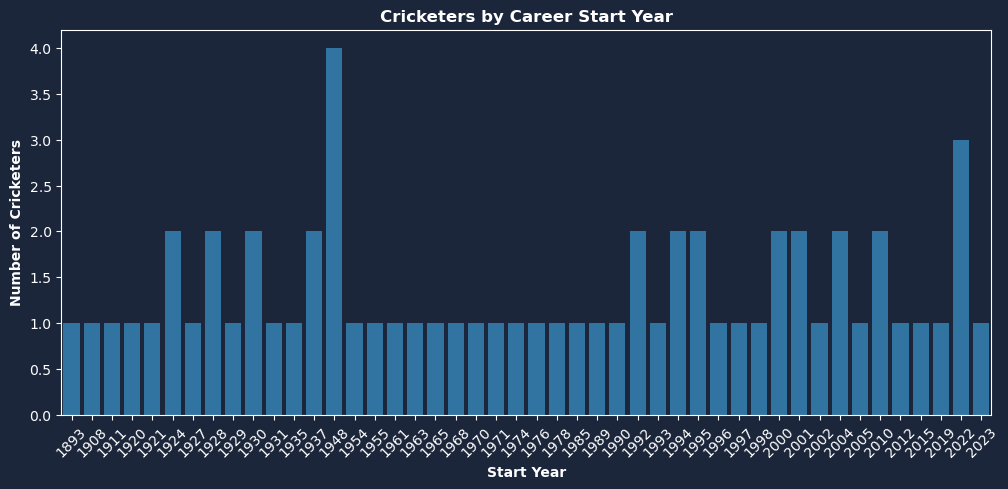

In [45]:
# 7. Cricketers by Start Date

start_year = df.groupby('Start_Date')['Player'].count()

print(start_year)

plt.figure(figsize=(12,5))
sns.barplot(x=start_year.index, y=start_year.values)
plt.title('Cricketers by Career Start Year')
plt.xlabel('Start Year')
plt.ylabel('Number of Cricketers')
plt.xticks(rotation=45)
plt.show()